## Modelling receiver area

In [1]:
from anemone.system import Loop, Receiver, ButterworthFilter
from anemone.forwards import Forward
import matplotlib.pyplot as plt
import numpy as np
import torch

In [2]:
x_offset = 0.
tx = Loop.square(3)
rx = Loop.square(2.5)
rx.x += x_offset

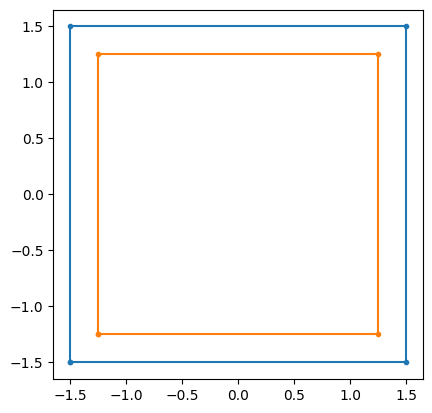

In [3]:
fig,ax = plt.subplots(1,1)
ax.plot(tx.x, tx.y, 'C0.-', label='Tx')
ax.plot(rx.x, rx.y, 'C1.-', label='Rx')
ax.set_aspect('equal')

c:\Users\au646858\OneDrive - Aarhus universitet\Documents\_repositories\anemone\.venv\lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


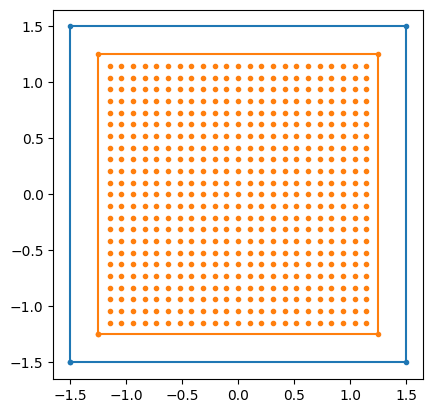

In [4]:
fig,ax = plt.subplots(1,1)
ax.plot(tx.x, tx.y, 'C0.-', label='Tx')
ax.plot(rx.x, rx.y, 'C1.-', label='Rx')

x,y = torch.meshgrid(torch.linspace(rx.x.min(), rx.x.max(), 25)[1:-1], torch.linspace(rx.y.min(), rx.y.max(), 25)[1:-1])
ax.plot(x.flatten(), y.flatten(), 'C1.', label='Rx')

ax.set_aspect('equal')


In [5]:
def make_rx(n_dipole):
    x,y = torch.meshgrid(torch.linspace(rx.x.min(), rx.x.max(), n_dipole+2)[1:-1], torch.linspace(rx.y.min(), rx.y.max(), n_dipole+2)[1:-1])
    rx_prof = Receiver(x=x.flatten(), y=y.flatten(), grid=False)
    weight = torch.ones_like(rx_prof.X) / rx_prof.X.numel()
    rx_prof.weighting = weight
    return rx_prof

In [6]:
fc = ButterworthFilter(8e5)
fc=None

C:\Users\au646858\OneDrive - Aarhus Universitet\Documents\_repositories\anemone\src\anemone\transforms\transforms.py:345: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4424.)
  return func(lamda/c.sqrt_twopi).T/torch.sqrt(lamda)


Text(0, 0.5, 'Relative error [%]')

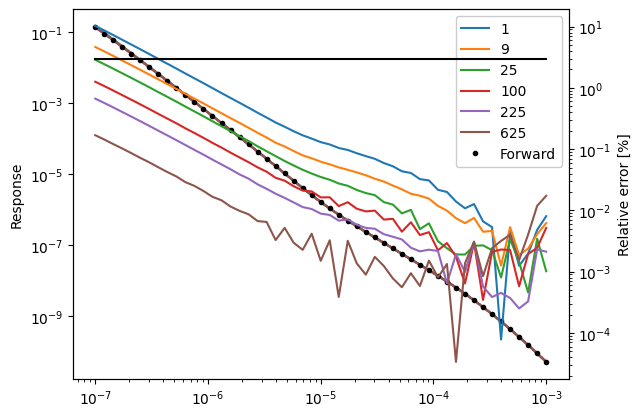

In [7]:
rho,thick = torch.tensor([40, 10, 100]), torch.tensor([20, 40])

rx25 = make_rx(32)
times = torch.logspace(-7, -3, 51)
fwr25 = Forward(tx, rx25, times, filterfunc=fc, tolerance=1e-6)
dbdt25 = fwr25(rho,thick).real

fig, ax = plt.subplots(1, 1)


ax2 = ax.twinx()

for i,n_dip in enumerate([1, 3, 5, 10, 15, 25]):
    crx = make_rx(n_dip)
    cfwr = Forward(tx, crx, times, filterfunc=fc, tolerance=1e-6)
    
    cdbdt = cfwr(rho,thick).real    

    ax.loglog(fwr25.times,  cdbdt, f'C{i}-', label=n_dip**2)
    ax.loglog(fwr25.times, -cdbdt, f'C{i}--')

    rel_err = ((cdbdt - dbdt25) / dbdt25).abs()

    ax2.loglog(fwr25.times, rel_err * 100, f'C{i}-')

    del cfwr

ax.loglog(fwr25.times,  dbdt25, 'k.', label='Forward')
ax.loglog(fwr25.times, -dbdt25, 'kx')
ax2.loglog(fwr25.times, 3.*torch.ones_like(fwr25.times), 'k-')


ax.legend(loc='upper right', framealpha=1.)
ax.set_ylabel('Response')
ax2.set_ylabel('Relative error [%]')

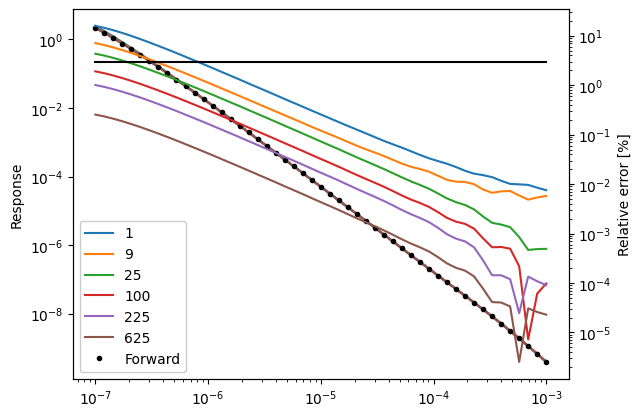

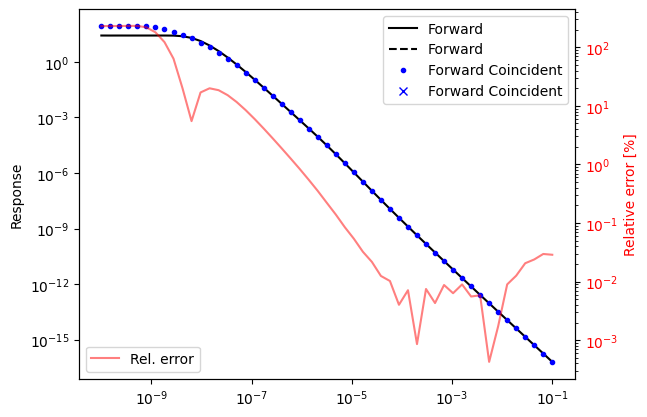

In [8]:
x,y = torch.meshgrid(torch.linspace(rx.x.min(), rx.x.max(), 7)[1:-1], torch.linspace(rx.y.min(), rx.y.max(), 7)[1:-1])

rx_prof = Receiver(x=x.flatten(), y=y.flatten(), grid=False)
weight = torch.ones_like(rx_prof.X) / rx_prof.X.numel()
rx_prof.weighting = weight

times = torch.logspace(-10, -1, 51)
fwr = Forward(tx, rx_prof, times, tolerance=None)

fwr0 = Forward(tx, Receiver(x=x_offset), times, tolerance=None)

dbdt = fwr(torch.tensor([40, 80]), torch.tensor([10])).real
dbdt0 = fwr0(torch.tensor([40, 80]), torch.tensor([10])).real

fig, ax = plt.subplots(1, 1)

ax.loglog(fwr.times,  dbdt0, 'k-', label='Forward')
ax.loglog(fwr.times, -dbdt0, 'k--', label='Forward')

ax.loglog(fwr.times,  dbdt, 'b.', label='Forward Coincident')
ax.loglog(fwr.times, -dbdt, 'bx', label='Forward Coincident')

ax.legend(loc='upper right')
ax.set_ylabel('Response')

ax2 = ax.twinx()
rel_err = ((dbdt - dbdt0) / dbdt0).abs()
ax2.loglog(fwr.times, rel_err * 100, 'r-', alpha=0.5, label='Rel. error')
ax2.set_ylabel('Relative error [%]', color='r')
ax2.tick_params(axis='y', labelcolor='r')
ax2.legend(loc='lower left')

In [9]:
tx = Loop.circle(30)
rx = Receiver(torch.linspace(0, 30, 21)[:-1])

In [10]:
times = torch.logspace(-7, -2, 51)

In [11]:
fwr = Forward(tx, rx, times, tolerance=None)

RuntimeError: Boolean value of Tensor with more than one value is ambiguous

In [ ]:
dbdt = fwr(torch.tensor([40, 80]), torch.tensor([10]))

RuntimeError: einsum(): the number of subscripts in the equation (2) does not match the number of dimensions (3) for operand 0 and no ellipsis was given

In [9]:
dr = torch.gradient(rx.x)[0]
ring_area = dr * rx.x*2*np.pi
ring_area[0] = (0.5*dr[0])**2 * np.pi

In [10]:
fwr.H2t = (fwr.H2t * ring_area[None, :, None]).sum(1)

In [11]:
dbdt = fwr(torch.tensor([40, 80]), torch.tensor([10])) / ring_area.sum()

In [12]:
fwr0 = Forward(tx, Receiver(), times, tolerance=None)
dbdt0 = fwr0(torch.tensor([40, 80]), torch.tensor([10]))

In [39]:
ring_area = ring_area / ring_area.sum()

rx1 = Receiver(rx.x, weighting=ring_area)
fwr1 = Forward(tx, rx1, times, tolerance=None)
fwr1.H2t = fwr1.H2t.real

dbdt1 = fwr1(torch.tensor([40, 80]), torch.tensor([10]))

In [40]:
from anemone.physics import rte_halfspace

13783


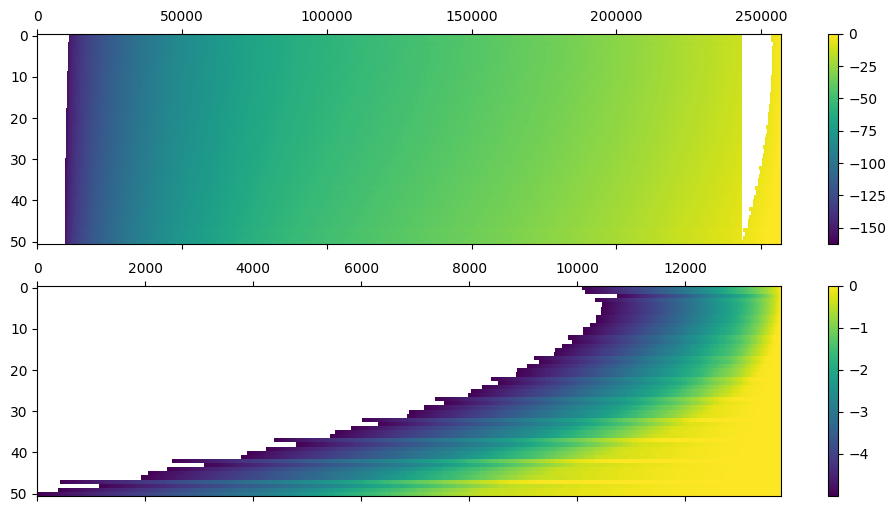

In [41]:
bigW = (fwr1.H2t*rte_halfspace(1./torch.tensor([100.]), fwr1.omega, fwr1.lamda).real).abs()#.sum(0)
i_Hsort = (bigW).sum(0).argsort()

bigWsort = bigW[:, i_Hsort]
bigWsort = bigWsort.cumsum(dim=1)/bigWsort.sum(dim=1, keepdims=True)
idx = torch.searchsorted(bigWsort, torch.ones((51,1))*1e-5, right=True).min()
i_Hsort = i_Hsort[idx:]

print(len(i_Hsort))

fwr1.H2t = fwr1.H2t[:, i_Hsort]
fwr1.omega = fwr1.omega[i_Hsort]
fwr1.lamda = fwr1.lamda[i_Hsort]

smallWsort = bigWsort[:, idx:]

fwr1.H2t[smallWsort<1e-5] = 0
smallWsort[smallWsort<1e-5] = 0


fig,axs=plt.subplots(2,1, figsize=(12,6))
pcm=axs[0].matshow(bigWsort.log10(), aspect='auto')
plt.colorbar(pcm, ax=axs[0])

pcm = axs[1].matshow(smallWsort.log10(), aspect='auto')
plt.colorbar(pcm, ax=axs[1])

<Figure size 640x480 with 0 Axes>

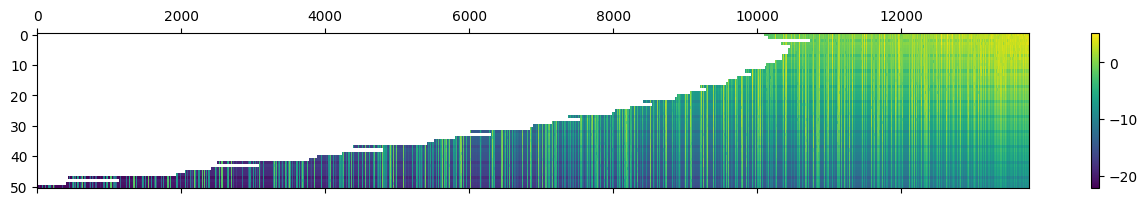

In [42]:
plt.figure()
pcm=plt.matshow(fwr1.H2t.real.abs().log10(), aspect='auto')
plt.colorbar(pcm)

In [47]:
dbdt0 = fwr0(torch.tensor([40, 80])/2., torch.tensor([10]))

In [48]:
dbdt1 = fwr1(torch.tensor([40, 80])/2., torch.tensor([10]))

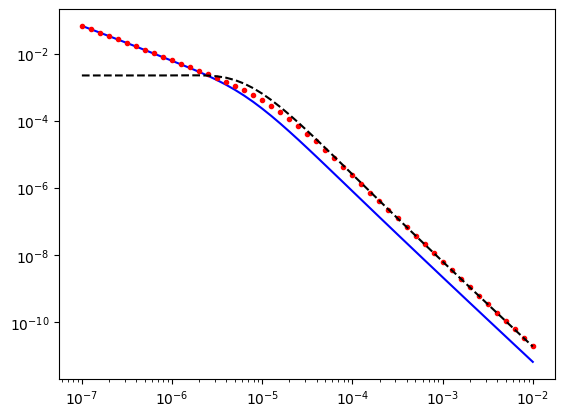

In [49]:
plt.figure()
plt.loglog(fwr.times, dbdt.real, 'b-', label='Forward Coincident')
plt.loglog(fwr.times, dbdt1.real, 'r.', label='Forward')

plt.loglog(fwr.times, dbdt0.real, 'k--', label='Forward')


In [19]:
area = 30**2 * np.pi
print(ring_area.sum(), area)

tensor(1., dtype=torch.float64) 2827.4333882308138


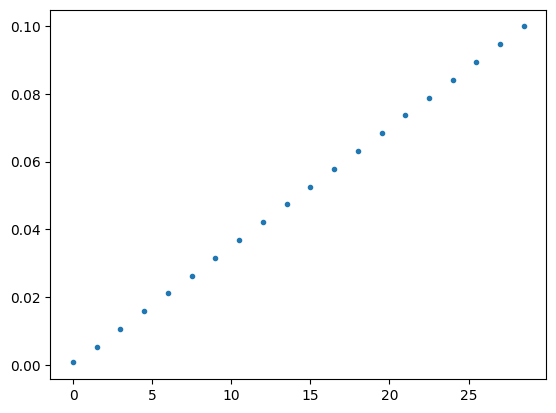

In [20]:
plt.figure()
plt.plot(rx.x, ring_area, '.')

In [1]:
from anemone import constants as c
from anemone.transforms import factorial
from anemone.system import Loop, Receiver, ButterworthFilter
from anemone.forwards import Forward
import matplotlib.pyplot as plt
import numpy as np
import torch

def hzdt_halfspace_coincident_circle_loop(times, rho, r, I=1., max_terms=50):

    sigma = 1./rho
    theta = torch.sqrt(0.25*c.mu0*sigma / times)
    dhdt = 1./(c.mu0*sigma*r**3)*(3*torch.erf(theta*r)-2*theta*r*(3+2*theta**2*r**2)*torch.exp(-theta**2*r**2)/c.sqrt_pi)

    m = 0.
    summation = 0.
    while m<max_terms:
        denmoninator = (-1)**m * factorial(2*m+2) * (theta*r)**(2*m)
        delta = denmoninator / (2*m+5)

        delta /= factorial(m)
        delta /= factorial(m+1)
        delta /= factorial(m+2)
        
        summation += delta
        m += 1
        if torch.all(torch.abs(delta / summation) < 1e-6):
            break
    print(f'broke at {m} terms')

    dhdt = 2*I*r*c.mu0*c.sqrt_pi * (theta*r)**3 * summation / times

    return dhdt


In [121]:
def hzdt_halfspace_coincident_circle_loop(times, rho, r, I=1., max_terms=200):
    sigma = 1. / rho
    theta = torch.sqrt(0.25 * c.mu0 * sigma / times)  # shape (n_times,)
    x2 = (theta * r) ** 2                              # (theta*r)^2, shape (n_times,)

    # Compute series sum_{m=0}^inf a_m via term ratios (stable, no large factorials)
    # Term m=0: (2*0+2)! * x^0 / (0! * 1! * 2! * 5) = 2 / (1*1*2*5) = 1/5
    term = torch.ones_like(x2) / 5.
    summation = term.clone()

    for m in range(max_terms - 1):
        ratio = -(2*m+4) * (2*m+3) * (2*m+5) * x2 / ((m+1) * (m+2) * (m+3) * (2*m+7))
        term = term * ratio
        summation = summation + term
        if torch.all(torch.abs(term / summation) < 1e-12):
            break

    dhdt = 2 * I * r * c.mu0 * c.sqrt_pi * (theta * r)**3 * summation / times
    return dhdt

In [221]:
def hzdt_halfspace_coincident_circle_loop(times, rho, r, I=1., max_terms=2000):
    sigma = 1. / rho
    # Use float64 throughout for extended range
    times64 = times.double()
    theta = torch.sqrt(0.25 * c.mu0 * sigma[:, None] / times64[None,:])
    tr = theta * r
    x2 = tr ** 2

    term = torch.ones_like(x2) / 5.
    summation = term.clone()
    for m in range(max_terms - 1):
        ratio = -(2*m+4) * (2*m+3) * (2*m+5) * x2 / ((m+1) * (m+2) * (m+3) * (2*m+7))
        term = term * ratio
        summation = summation + term
        if torch.all(torch.abs(term / summation) < 1e-12):
            break

    dhdt = 2 * I * r * c.mu0 * c.sqrt_pi * tr**3 * summation / times64[None,:]
    return dhdt.to(times.dtype)

In [250]:
radius = 1.
rho = torch.logspace(0,3,7)
times = torch.logspace(-7, -3, 51)
dhdt_analytic = hzdt_halfspace_coincident_circle_loop(times, rho, radius) / (torch.pi*radius**2)

In [251]:
tx1 = Loop.circle(radius)
rx1= Receiver()
fwr1 = Forward(tx1, rx1, times)
dbdt1 = fwr1(rho[None,:]*torch.ones(2)[:,None], torch.ones(1)*20).real

In [252]:
r_samples = torch.linspace(0, radius, 10, dtype=torch.double)
txC = Loop.circle(radius)
rxC = Receiver(x=r_samples[:-1])


ring_area = torch.diff(torch.pi*r_samples**2, axis=0)
ring_area *=  (torch.pi*radius**2) / ring_area.sum()
rxC.weighting = ring_area / ring_area.sum()#(torch.pi*radius**2)

fwrC = Forward(txC, rxC, times)
dbdtC = fwrC(rho[None,:]*torch.ones(2)[:,None], torch.ones(1)*20).real


In [253]:
r_samples = torch.linspace(0, radius, 1000, dtype=torch.double)
txC = Loop.circle(radius)
rxC = Receiver(x=r_samples[:-1])


ring_area = torch.diff(torch.pi*r_samples**2, axis=0)
ring_area *=  (torch.pi*radius**2) / ring_area.sum()
rxC.weighting = ring_area / ring_area.sum()#(torch.pi*radius**2)

fwrC2 = Forward(txC, rxC, times)
dbdtC2 = fwrC2(rho[None,:]*torch.ones(2)[:,None], torch.ones(1)*20).real


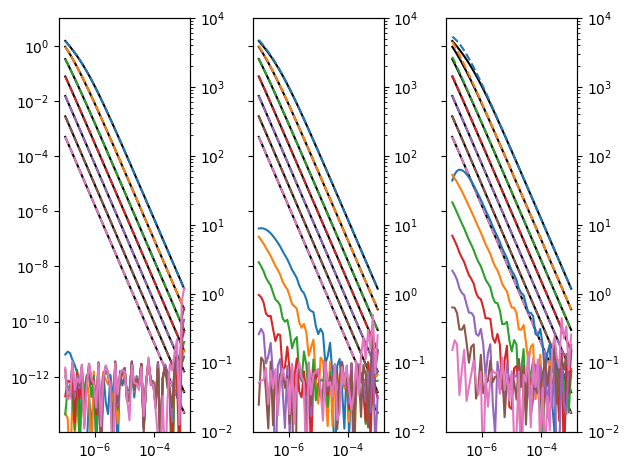

In [255]:
fig,axs = plt.subplots(1,3, sharex=True, sharey=True)

for ax,dbdt in zip(axs, [dbdtC2, dbdtC, dbdt1]):

    ax.loglog(times, dhdt_analytic.T, 'k-')
    ax.loglog(times, dbdt.T, '--')

    ax2 = ax.twinx()

    relerr1 = torch.abs((dbdt - dhdt_analytic) / dhdt_analytic)*100.
    ax2.loglog(times, relerr1.T)
    ax2.set_ylim(1e-2, 1e4)

plt.tight_layout()